# Starter Code — Stereo Vision dengan 1 HP

**Petunjuk persiapan foto, alat, dan hal yang harus dicatat ada di `README.md`.** Notebook ini untuk menjalankan kode dan mengisi hasil. Jalankan **A → G** berurutan.

## A — Konfigurasi dan pemeriksaan file
Isi tiga nilai yang diukur. Untuk Colab, ubah `UPLOAD_ZIP = True`.

In [37]:
from pathlib import Path
import os, zipfile, csv
import cv2
import numpy as np
import matplotlib.pyplot as plt

PATTERN_SIZE = (9, 6)        # sudut dalam; papan cetak 10 x 7 kotak
SQUARE_SIZE_MM = 25.0        # GANTI dengan ukuran satu kotak hasil penggaris
BASELINE_CM = 10.0           # GANTI dengan perpindahan pusat kamera L -> R
UPLOAD_ZIP = False          # True hanya di Google Colab
DATA_DIR = Path('.') if not UPLOAD_ZIP else Path('/content/PROJEK_COMVIS')

CAL_DIR = DATA_DIR/'calibration'
STEREO_DIR = DATA_DIR/'stereo'
OUT = DATA_DIR/'output'
OUT.mkdir(parents=True, exist_ok=True)
image_ext = {'.jpg','.jpeg','.png','.bmp'}
cal_files = sorted(p for p in CAL_DIR.iterdir() if p.suffix.lower() in image_ext) if CAL_DIR.exists() else []
L_PATH, R_PATH = STEREO_DIR/'kiri 50.jpeg', STEREO_DIR/'kanan 50.jpeg'
print('OpenCV:',cv2.__version__)
print('Foto kalibrasi:',len(cal_files),'| kiri:',L_PATH.exists(),'| kanan:',R_PATH.exists())
print('Kotak:',SQUARE_SIZE_MM,'mm | baseline:',BASELINE_CM,'cm')
if SQUARE_SIZE_MM <= 0 or BASELINE_CM <= 0: raise ValueError('Ukuran kotak dan baseline harus positif.')
if len(cal_files) < 10: raise RuntimeError('Sediakan setidaknya 10 foto kalibrasi (disarankan 15–25).')
if not L_PATH.exists() or not R_PATH.exists(): raise FileNotFoundError('Periksa stereo/kiri 100.jpeg dan stereo/kanan 100.jpeg')

OpenCV: 5.1.0
Foto kalibrasi: 21 | kiri: True | kanan: True
Kotak: 25.0 mm | baseline: 10.0 cm


## B — Deteksi sudut chessboard dan ukur jarak dalam piksel
Hasil `contoh jarak 2 sudut` adalah nilai **foto**, bukan focal length. Foto gagal otomatis dilewati.

Foto valid: 16 | Gagal: 5
Foto gagal: ['cal 13.jpeg', 'cal 16.jpeg', 'cal 2.jpeg', 'cal 3.jpeg', 'cal 4.jpeg']
Contoh jarak dua sudut dalam piksel: 84.12


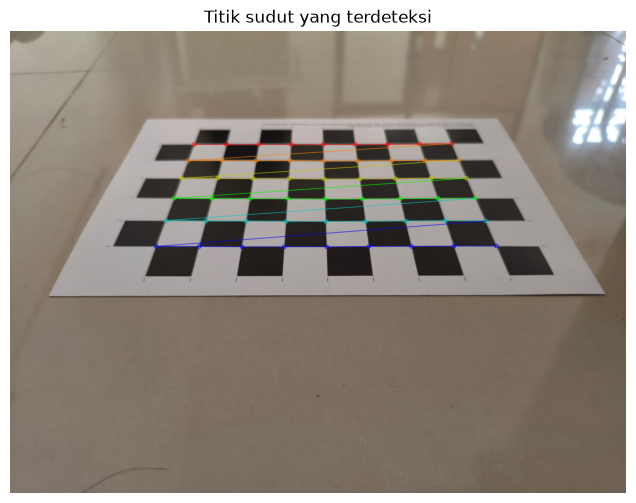

In [38]:
cols, rows = PATTERN_SIZE
obj = np.zeros((cols*rows,3),np.float32)
obj[:,:2] = np.mgrid[0:cols,0:rows].T.reshape(-1,2) * SQUARE_SIZE_MM
objpoints, imgpoints, ok_files, bad_files, spacings = [],[],[],[],[]
size_wh = None
preview = None
for path in cal_files:
    img = cv2.imread(str(path))
    if img is None: bad_files.append(path.name); continue
    gray = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
    wh = (gray.shape[1],gray.shape[0])
    if size_wh is None: size_wh=wh
    if wh != size_wh:
        bad_files.append(path.name+' (resolusi berbeda)'); continue
    found,corners = cv2.findChessboardCornersSB(gray, PATTERN_SIZE)
    if not found: bad_files.append(path.name); continue
    corners = corners.astype(np.float32)
    objpoints.append(obj.copy()); imgpoints.append(corners)
    ok_files.append(path.name)
    spacings.append(float(np.linalg.norm(corners[1,0]-corners[0,0])))
    if preview is None:
        preview=img.copy()
        cv2.drawChessboardCorners(preview,PATTERN_SIZE,corners,True)
print('Foto valid:',len(ok_files),'| Gagal:',len(bad_files))
print('Foto gagal:',bad_files)
print('Contoh jarak dua sudut dalam piksel:', round(spacings[0],2) if spacings else None)
if preview is not None:
    plt.figure(figsize=(10,6));plt.imshow(cv2.cvtColor(preview,cv2.COLOR_BGR2RGB));plt.title('Titik sudut yang terdeteksi');plt.axis('off');plt.show()
    cv2.imwrite(str(OUT/'corners_preview.jpg'),preview)
if len(ok_files) < 10: raise RuntimeError('Titik sudut berhasil dideteksi pada <10 foto. Ulangi/ambil foto baru.')

## C — Kalibrasi kamera: hasil `fx`, `fy`, `cx`, `cy`
Periksa RMS dan simpan hasilnya. **Tidak ada angka focal length asumsi**.

In [39]:
rms,K,dist,rvecs,tvecs=cv2.calibrateCamera(objpoints,imgpoints,size_wh,None,None)
fx,fy,cx,cy = K[0,0],K[1,1],K[0,2],K[1,2]
print('Resolusi kalibrasi:',size_wh)
print('K =\n',K)
print(f'fx={fx:.2f} px | fy={fy:.2f} px | cx={cx:.2f} px | cy={cy:.2f} px')
print(f'RMS reprojection error={rms:.3f} px')
print('Distorsi:',dist.ravel())
np.savez(OUT/'calibration.npz',K=K,dist=dist,image_wh=size_wh,rms=rms,square_size_mm=SQUARE_SIZE_MM)
if not np.isfinite(rms) or rms > 2.0:
    print('PERHATIAN: RMS cukup besar. Periksa foto kalibrasi dan kesesuaian pola.')

Resolusi kalibrasi: (1600, 1200)
K =
 [[1.25908570e+03 0.00000000e+00 7.95960981e+02]
 [0.00000000e+00 1.25630623e+03 5.99457531e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
fx=1259.09 px | fy=1256.31 px | cx=795.96 px | cy=599.46 px
RMS reprojection error=0.531 px
Distorsi: [ 1.26570928e-01 -4.42464976e-01 -2.78403051e-03 -3.93386393e-04
  1.91510631e-01]


## D — Baca stereo, koreksi distorsi, dan cek alignment
Matching global dipakai untuk alignment; visualisasi feature match difokuskan ke botol pink. Jika foto kiri/kanan tidak cukup sejajar, **kode berhenti**.

Orientasi stereo portrait; undistortion kalibrasi dilewati untuk menghindari matriks resolusi yang salah.
Matching: 337 | Inlier: 235
Median beda baris = 0.59 px | Median disparity = -1.19 px | Fraksi disparity positif = 41.7%
Feature botol pink: 476 match | 139 inlier


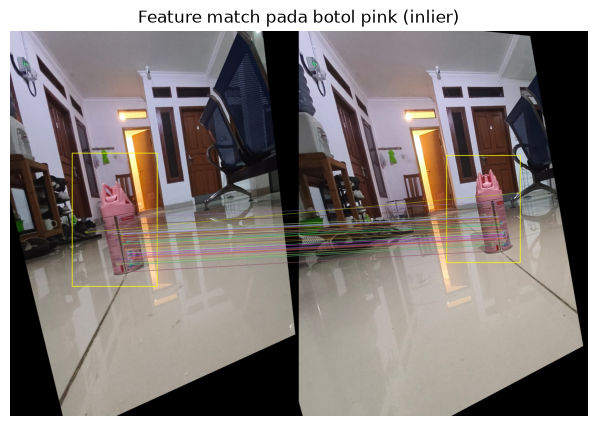

Alignment lolos pemeriksaan awal (bukan jaminan rectification sempurna).


In [40]:
left=cv2.imread(str(L_PATH));right=cv2.imread(str(R_PATH))
if left is None or right is None: raise ValueError('Gagal membaca foto stereo')
if left.shape!=right.shape:
    raise ValueError(f'Resolusi foto stereo berbeda: kiri={left.shape[1]}x{left.shape[0]}, kanan={right.shape[1]}x{right.shape[0]}')
stereo_wh=(left.shape[1],left.shape[0])
use_calibration_undistort=(stereo_wh==size_wh)
if stereo_wh!=size_wh:
    if stereo_wh==(size_wh[1],size_wh[0]):
        size_wh=stereo_wh
        print('Orientasi stereo portrait; undistortion kalibrasi dilewati untuk menghindari matriks resolusi yang salah.')
    else:
        raise ValueError(f'Resolusi stereo tidak cocok. Kalibrasi={size_wh}, stereo={stereo_wh}. Ambil foto pada orientasi yang sama.')
left_u=left.copy()
right_u=right.copy()
if use_calibration_undistort:
    map1,map2=cv2.initUndistortRectifyMap(K,dist,None,K,size_wh,cv2.CV_32FC1)
    left_u=cv2.remap(left,map1,map2,cv2.INTER_LINEAR)
    right_u=cv2.remap(right,map1,map2,cv2.INTER_LINEAR)
lg=cv2.cvtColor(left_u,cv2.COLOR_BGR2GRAY)
rg=cv2.cvtColor(right_u,cv2.COLOR_BGR2GRAY)
orb=cv2.ORB_create(nfeatures=4500)
k1,des1=orb.detectAndCompute(lg,None)
k2,des2=orb.detectAndCompute(rg,None)
if des1 is None or des2 is None: raise RuntimeError('Fitur foto kurang. Gunakan objek/latar bertekstur.')
matches=cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(des1,des2,k=2)
good=[a for a,b in matches if a.distance < 0.75*b.distance]
if len(good) < 20: raise RuntimeError('Terlalu sedikit feature match. Ulangi foto dengan lebih banyak tekstur.')
pL=np.float32([k1[m.queryIdx].pt for m in good]);pR=np.float32([k2[m.trainIdx].pt for m in good])
# Fundamental matrix hanya untuk filter outlier, bukan mengganti rectification
F,mask=cv2.findFundamentalMat(pL,pR,cv2.FM_RANSAC,1.5,0.99)
if mask is None: raise RuntimeError('RANSAC gagal: pasangan foto sulit dicocokkan.')
inlier=mask.ravel().astype(bool)
if inlier.sum()<15: raise RuntimeError('Inlier kurang dari 15. Ulangi foto.')
rect_ok,H1,H2=cv2.stereoRectifyUncalibrated(pL[inlier],pR[inlier],F,size_wh,threshold=5)
if not rect_ok: raise RuntimeError('Rectification gagal. Ambil ulang pasangan foto dari posisi sejajar.')
candidates=[]
for h_left,h_right in ((H1,H2),(H2,H1)):
    rectL=cv2.perspectiveTransform(pL[inlier][None,:,:],h_left)[0]
    rectR=cv2.perspectiveTransform(pR[inlier][None,:,:],h_right)[0]
    dy=np.abs(rectL[:,1]-rectR[:,1])
    dx=rectL[:,0]-rectR[:,0]
    candidates.append((float(np.median(dy)),float(np.median(dx)),float(np.mean(dx>0)),h_left,h_right))
valid=[c for c in candidates if c[0]<=2.0 and c[2]>=0.35]
if not valid:
    raise RuntimeError('Tidak ada arah rectification yang memenuhi penyelarasan. Ulangi pasangan foto.')
median_dy,median_dx,positive_fraction,H1,H2=min(valid,key=lambda c:(c[0],-c[1]))
left_u=cv2.warpPerspective(left_u,H1,size_wh,flags=cv2.INTER_LINEAR)
right_u=cv2.warpPerspective(right_u,H2,size_wh,flags=cv2.INTER_LINEAR)
print('Matching:',len(good),'| Inlier:',int(inlier.sum()))
print(f'Median beda baris = {median_dy:.2f} px | Median disparity = {median_dx:.2f} px | Fraksi disparity positif = {positive_fraction:.1%}')
def pink_bottle_feature_mask(image):
    h,w=image.shape[:2]
    hsv=cv2.cvtColor(image,cv2.COLOR_BGR2HSV)
    pink=cv2.inRange(hsv,np.array([145,30,45],np.uint8),np.array([179,255,255],np.uint8))
    pink[:int(0.35*h),:]=0
    pink=cv2.morphologyEx(pink,cv2.MORPH_CLOSE,np.ones((5,5),np.uint8))
    count,labels,stats,_=cv2.connectedComponentsWithStats(pink)
    candidates=[]
    for x,y,bw,bh,area in stats[1:]:
        aspect=bh/max(bw,1)
        if area>=300 and 1.2<=aspect<=7 and y>=0.35*h:
            candidates.append((int(area),int(x),int(y),int(bw),int(bh)))
    if not candidates:
        raise RuntimeError('Botol pink tidak terdeteksi. Pastikan botol terlihat jelas di kedua foto.')
    _,x,y,bw,bh=max(candidates)
    pad=max(12,int(max(bw,bh)*0.12))
    x0,y0=max(0,x-pad),max(0,y-pad)
    x1,y1=min(w,x+bw+pad),min(h,y+bh+pad)
    feature_mask=np.zeros((h,w),np.uint8)
    feature_mask[y0:y1,x0:x1]=255
    return feature_mask,(x0,y0,x1,y1)

pink_mask_l,pink_box_l=pink_bottle_feature_mask(left_u)
pink_mask_r,pink_box_r=pink_bottle_feature_mask(right_u)
lg=cv2.cvtColor(left_u,cv2.COLOR_BGR2GRAY)
rg=cv2.cvtColor(right_u,cv2.COLOR_BGR2GRAY)
pink_orb=cv2.ORB_create(nfeatures=5000,fastThreshold=5)
pink_kp_l,pink_desc_l=pink_orb.detectAndCompute(lg,pink_mask_l)
pink_kp_r,pink_desc_r=pink_orb.detectAndCompute(rg,pink_mask_r)
if pink_desc_l is None or pink_desc_r is None:
    raise RuntimeError('Fitur botol pink tidak cukup. Gunakan foto yang lebih tajam dan bertekstur.')
pink_pairs=cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(pink_desc_l,pink_desc_r,k=2)
pink_good=[m for m,n in pink_pairs if m.distance<0.85*n.distance]
if len(pink_good)<8:
    raise RuntimeError(f'Hanya {len(pink_good)} feature match botol pink. Periksa foto dan pencahayaan.')
pink_pL=np.float32([pink_kp_l[m.queryIdx].pt for m in pink_good])
pink_pR=np.float32([pink_kp_r[m.trainIdx].pt for m in pink_good])
_,pink_inlier_mask=cv2.findFundamentalMat(pink_pL,pink_pR,cv2.FM_RANSAC,2.0,0.99)
if pink_inlier_mask is None or int(pink_inlier_mask.sum())<8:
    raise RuntimeError('Feature match botol pink tidak cukup konsisten. Ambil ulang foto tanpa mengubah posisi botol.')
pink_inliers=[m for m,keep in zip(pink_good,pink_inlier_mask.ravel().astype(bool)) if keep]
left_vis=left_u.copy();right_vis=right_u.copy()
cv2.rectangle(left_vis,pink_box_l[:2],(pink_box_l[2]-1,pink_box_l[3]-1),(0,255,255),2)
cv2.rectangle(right_vis,pink_box_r[:2],(pink_box_r[2]-1,pink_box_r[3]-1),(0,255,255),2)
vis=cv2.drawMatches(left_vis,pink_kp_l,right_vis,pink_kp_r,pink_inliers[:40],None,flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
print(f'Feature botol pink: {len(pink_good)} match | {len(pink_inliers)} inlier')
plt.figure(figsize=(13,5));plt.imshow(cv2.cvtColor(vis,cv2.COLOR_BGR2RGB));plt.title('Feature match pada botol pink (inlier)');plt.axis('off');plt.show()
cv2.imwrite(str(OUT/'matches.jpg'),vis)
ALIGNMENT_OK = (median_dy<=2.0 and positive_fraction>=0.35)
if not ALIGNMENT_OK:
    raise RuntimeError('Alignment belum cukup baik. Ulangi foto stereo tanpa rotasi/naik-turun; jangan pakai hasil depth.')
print('Alignment lolos pemeriksaan awal (bukan jaminan rectification sempurna).')

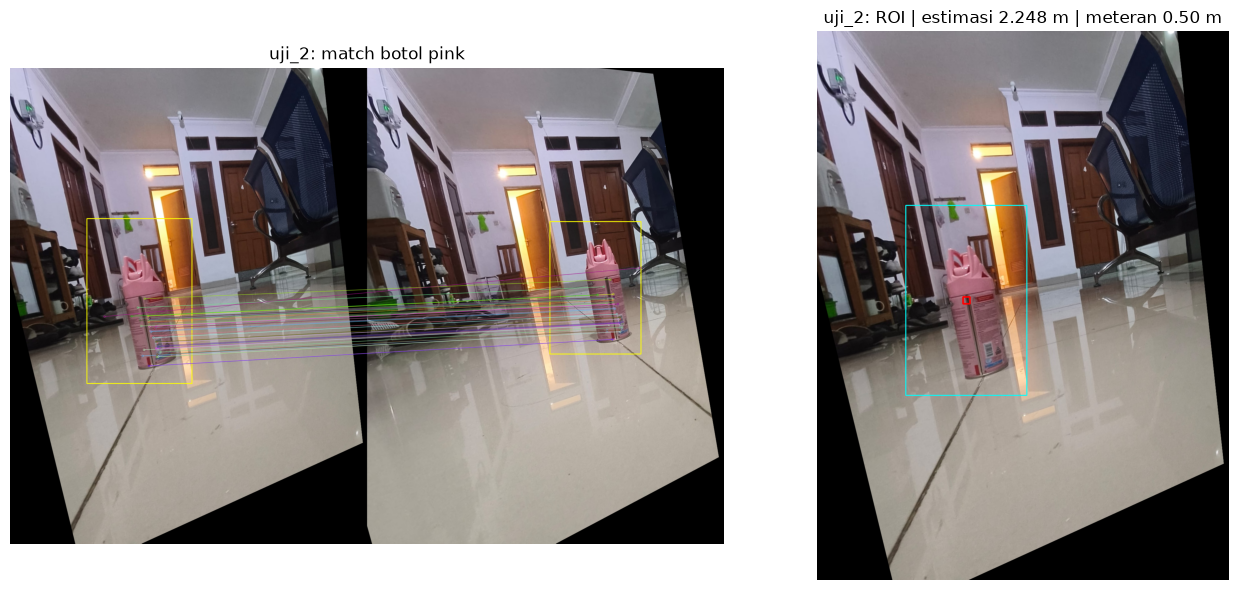

uji_2 (50 cm): match global=337, inlier global=235, match botol=476, inlier botol=139
ROI valid=73 | disparity=56.00 px | depth=2.2484 m | meteran=0.50 m | error=349.67%
Hasil tersimpan: output\hasil_pengukuran.csv


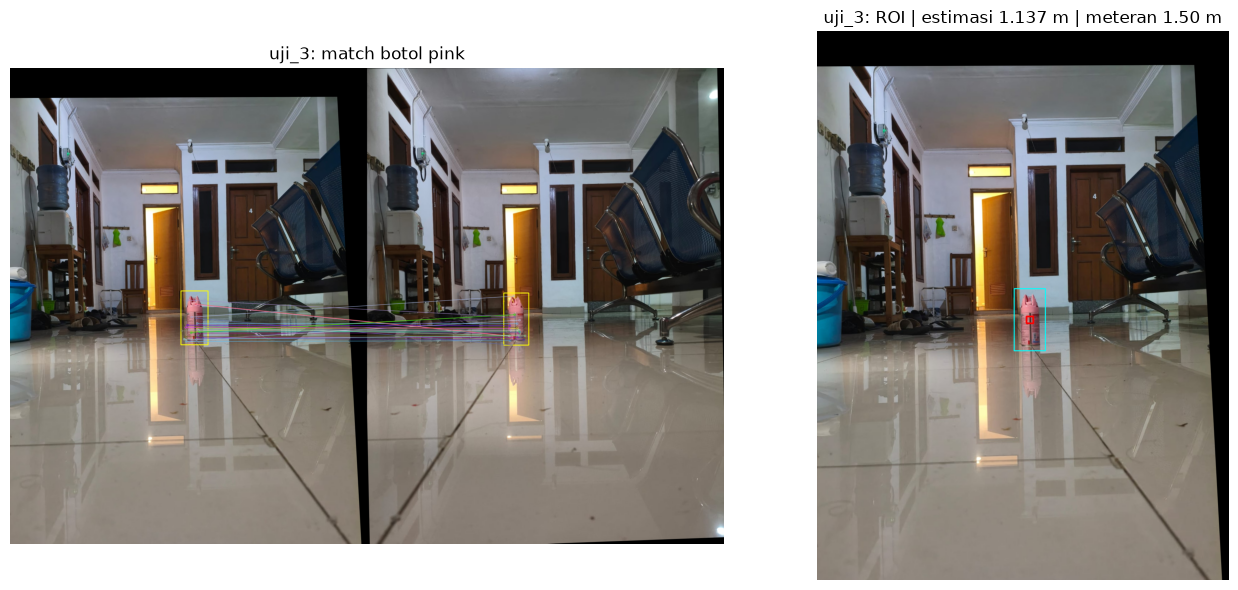

uji_3 (150 cm): match global=632, inlier global=442, match botol=117, inlier botol=30
ROI valid=166 | disparity=110.75 px | depth=1.1369 m | meteran=1.50 m | error=24.21%
Hasil tersimpan: output\hasil_pengukuran.csv


In [46]:
def run_stereo_trial(distance_cm,test_id):
    true_depth_m=distance_cm/100.0
    left_path=STEREO_DIR/f'kiri {distance_cm}.jpeg'
    right_path=STEREO_DIR/f'kanan {distance_cm}.jpeg'
    if not left_path.exists() or not right_path.exists():
        raise FileNotFoundError(f'Foto untuk uji {distance_cm} cm tidak ditemukan.')
    calibration=np.load(OUT/'calibration.npz')
    K_test=calibration['K'];dist_test=calibration['dist']
    calibration_wh=tuple(int(v) for v in calibration['image_wh'])
    fx_test=float(K_test[0,0]);fy_test=float(K_test[1,1])
    cv2.setRNGSeed(0)
    left=cv2.imread(str(left_path));right=cv2.imread(str(right_path))
    if left is None or right is None:raise ValueError(f'Gagal membaca foto uji {distance_cm} cm.')
    if left.shape!=right.shape:raise ValueError('Resolusi foto kiri dan kanan berbeda.')
    image_wh=(left.shape[1],left.shape[0])
    left_u=left.copy();right_u=right.copy()
    if image_wh==calibration_wh:
        map1,map2=cv2.initUndistortRectifyMap(K_test,dist_test,None,K_test,image_wh,cv2.CV_32FC1)
        left_u=cv2.remap(left,map1,map2,cv2.INTER_LINEAR)
        right_u=cv2.remap(right,map1,map2,cv2.INTER_LINEAR)
    elif image_wh!=(calibration_wh[1],calibration_wh[0]):
        raise ValueError(f'Resolusi foto {image_wh} tidak cocok dengan kalibrasi {calibration_wh}.')
    gray_l=cv2.cvtColor(left_u,cv2.COLOR_BGR2GRAY)
    gray_r=cv2.cvtColor(right_u,cv2.COLOR_BGR2GRAY)
    orb=cv2.ORB_create(nfeatures=4500)
    kp_l,desc_l=orb.detectAndCompute(gray_l,None)
    kp_r,desc_r=orb.detectAndCompute(gray_r,None)
    if desc_l is None or desc_r is None:raise RuntimeError('Foto stereo tidak memiliki cukup fitur.')
    pairs=cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(desc_l,desc_r,k=2)
    good=[m for m,n in pairs if m.distance<0.75*n.distance]
    if len(good)<20:raise RuntimeError(f'Uji {distance_cm} cm: match global kurang dari 20.')
    p_l=np.float32([kp_l[m.queryIdx].pt for m in good])
    p_r=np.float32([kp_r[m.trainIdx].pt for m in good])
    cv2.setRNGSeed(0)
    F,mask=cv2.findFundamentalMat(p_l,p_r,cv2.FM_RANSAC,1.5,0.99)
    if F is None or mask is None:raise RuntimeError(f'RANSAC gagal pada uji {distance_cm} cm.')
    inliers=mask.ravel().astype(bool)
    if int(inliers.sum())<15:raise RuntimeError(f'Uji {distance_cm} cm: inlier global kurang dari 15.')
    rect_ok,H1_test,H2_test=cv2.stereoRectifyUncalibrated(p_l[inliers],p_r[inliers],F,image_wh,threshold=5)
    if not rect_ok:raise RuntimeError(f'Rectification gagal pada uji {distance_cm} cm.')
    candidates=[]
    for h_l,h_r in ((H1_test,H2_test),(H2_test,H1_test)):
        rect_l=cv2.perspectiveTransform(p_l[inliers][None,:,:],h_l)[0]
        rect_r=cv2.perspectiveTransform(p_r[inliers][None,:,:],h_r)[0]
        vertical=np.abs(rect_l[:,1]-rect_r[:,1])
        disparity=rect_l[:,0]-rect_r[:,0]
        candidates.append((float(np.median(vertical)),float(np.median(disparity)),float(np.mean(disparity>0)),h_l,h_r))
    aligned=[c for c in candidates if c[0]<=2.0]
    if not aligned:raise RuntimeError(f'Uji {distance_cm} cm gagal pemeriksaan alignment.')
    median_vertical,_,positive_fraction,H1_test,H2_test=min(aligned,key=lambda c:(c[0],-c[1]))
    left_u=cv2.warpPerspective(left_u,H1_test,image_wh,flags=cv2.INTER_LINEAR)
    right_u=cv2.warpPerspective(right_u,H2_test,image_wh,flags=cv2.INTER_LINEAR)
    if positive_fraction<0.35:
        left_u,right_u=right_u,left_u
    bottle_mask_l,bottle_box_l=pink_bottle_feature_mask(left_u)
    bottle_mask_r,bottle_box_r=pink_bottle_feature_mask(right_u)
    gray_l=cv2.cvtColor(left_u,cv2.COLOR_BGR2GRAY)
    gray_r=cv2.cvtColor(right_u,cv2.COLOR_BGR2GRAY)
    bottle_orb=cv2.ORB_create(nfeatures=5000,fastThreshold=5)
    bottle_kp_l,bottle_desc_l=bottle_orb.detectAndCompute(gray_l,bottle_mask_l)
    bottle_kp_r,bottle_desc_r=bottle_orb.detectAndCompute(gray_r,bottle_mask_r)
    if bottle_desc_l is None or bottle_desc_r is None:raise RuntimeError(f'Fitur botol tidak cukup pada uji {distance_cm} cm.')
    bottle_pairs=cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(bottle_desc_l,bottle_desc_r,k=2)
    bottle_good=[m for m,n in bottle_pairs if m.distance<0.85*n.distance]
    if len(bottle_good)<8:raise RuntimeError(f'Uji {distance_cm} cm: match botol pink kurang dari 8.')
    bottle_p_l=np.float32([bottle_kp_l[m.queryIdx].pt for m in bottle_good])
    bottle_p_r=np.float32([bottle_kp_r[m.trainIdx].pt for m in bottle_good])
    cv2.setRNGSeed(0)
    _,bottle_mask=cv2.findFundamentalMat(bottle_p_l,bottle_p_r,cv2.FM_RANSAC,2.0,0.99)
    if bottle_mask is None or int(bottle_mask.sum())<8:raise RuntimeError(f'Uji {distance_cm} cm: inlier botol pink kurang dari 8.')
    bottle_inliers=[m for m,keep in zip(bottle_good,bottle_mask.ravel().astype(bool)) if keep]
    sgbm=cv2.StereoSGBM_create(minDisparity=0,numDisparities=128,blockSize=7,P1=392,P2=1568,uniquenessRatio=10,speckleWindowSize=70,speckleRange=2,disp12MaxDiff=1,mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY)
    disparity=sgbm.compute(gray_l,gray_r).astype(np.float32)/16.0
    valid=np.isfinite(disparity)&(disparity>0.5)
    depth=np.full(disparity.shape,np.nan,np.float32)
    depth[valid]=(fx_test*(BASELINE_CM/100.0))/disparity[valid]
    roi_x=(bottle_box_l[0]+bottle_box_l[2])//2
    roi_y=(bottle_box_l[1]+bottle_box_l[3])//2
    radius=10
    x0,x1=max(0,roi_x-radius),min(depth.shape[1],roi_x+radius+1)
    y0,y1=max(0,roi_y-radius),min(depth.shape[0],roi_y+radius+1)
    roi_depth=depth[y0:y1,x0:x1]
    roi_disparity=disparity[y0:y1,x0:x1]
    roi_valid=np.isfinite(roi_depth)&(roi_depth>0)
    if int(roi_valid.sum())<10:raise RuntimeError(f'Uji {distance_cm} cm: piksel depth valid pada ROI botol kurang dari 10.')
    depth_est=float(np.median(roi_depth[roi_valid]))
    disparity_med=float(np.median(roi_disparity[roi_valid]))
    error_pct=abs(depth_est-true_depth_m)/true_depth_m*100
    record={'uji':test_id,'baseline_cm':BASELINE_CM,'square_size_mm':SQUARE_SIZE_MM,'fx_px':round(fx_test,3),'fy_px':round(fy_test,3),'rms_px':round(float(calibration['rms']),3),'median_vertical_error_px':round(median_vertical,3),'disparity_roi_px':round(disparity_med,3),'depth_est_m':round(depth_est,4),'depth_meter_m':round(true_depth_m,4),'error_pct':round(error_pct,2)}
    csv_path=OUT/'hasil_pengukuran.csv'
    rows=[]
    if csv_path.exists():
        with csv_path.open(encoding='utf-8',newline='') as fh:rows=list(csv.DictReader(fh))
    rows=[row for row in rows if row['uji']!=test_id]+[record]
    with csv_path.open('w',encoding='utf-8',newline='') as fh:
        writer=csv.DictWriter(fh,fieldnames=list(record));writer.writeheader();writer.writerows(rows)
    tag=test_id.replace(' ','_')
    np.save(OUT/f'disparity_px_{tag}.npy',np.where(valid,disparity,np.nan))
    np.save(OUT/f'depth_m_{tag}.npy',depth)
    left_vis=left_u.copy();right_vis=right_u.copy()
    cv2.rectangle(left_vis,bottle_box_l[:2],(bottle_box_l[2]-1,bottle_box_l[3]-1),(0,255,255),2)
    cv2.rectangle(right_vis,bottle_box_r[:2],(bottle_box_r[2]-1,bottle_box_r[3]-1),(0,255,255),2)
    matches_vis=cv2.drawMatches(left_vis,bottle_kp_l,right_vis,bottle_kp_r,bottle_inliers[:40],None,flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    cv2.imwrite(str(OUT/f'matches_{tag}.jpg'),matches_vis)
    roi_vis=cv2.cvtColor(left_u,cv2.COLOR_BGR2RGB).copy()
    cv2.rectangle(roi_vis,bottle_box_l[:2],(bottle_box_l[2]-1,bottle_box_l[3]-1),(0,255,255),2)
    cv2.rectangle(roi_vis,(x0,y0),(x1-1,y1-1),(255,0,0),3)
    fig,ax=plt.subplots(1,2,figsize=(14,6))
    ax[0].imshow(cv2.cvtColor(matches_vis,cv2.COLOR_BGR2RGB));ax[0].set_title(f'{test_id}: match botol pink')
    ax[1].imshow(roi_vis);ax[1].set_title(f'{test_id}: ROI | estimasi {depth_est:.3f} m | meteran {true_depth_m:.2f} m')
    for axis in ax:axis.axis('off')
    plt.tight_layout();plt.show()
    print(f'{test_id} ({distance_cm} cm): match global={len(good)}, inlier global={int(inliers.sum())}, match botol={len(bottle_good)}, inlier botol={len(bottle_inliers)}')
    print(f'ROI valid={int(roi_valid.sum())} | disparity={disparity_med:.2f} px | depth={depth_est:.4f} m | meteran={true_depth_m:.2f} m | error={error_pct:.2f}%')
    print('Hasil tersimpan:',csv_path)
    return record

hasil_uji_2=run_stereo_trial(50,'uji_2')
hasil_uji_3=run_stereo_trial(150,'uji_3')

## E — Hitung disparity dan depth map
Untuk melihat hasil, objek dekat biasanya memiliki disparity lebih besar. Nilai tak valid dibiarkan sebagai `NaN`.

Piksel disparity valid: 29.9%


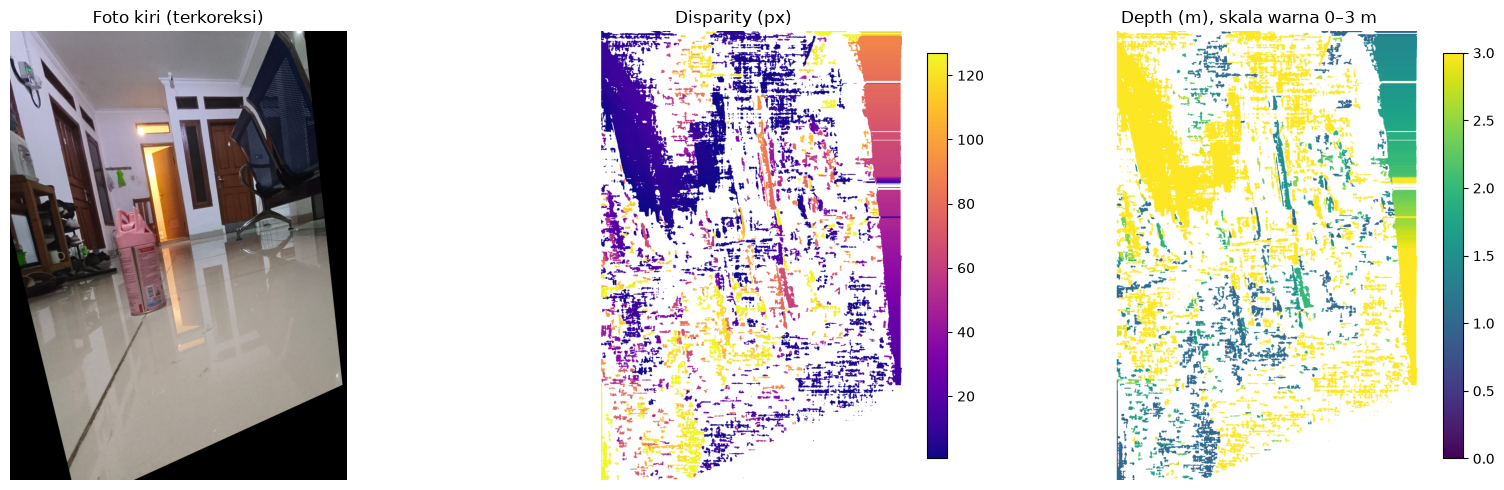

True

In [41]:
if not ALIGNMENT_OK: raise RuntimeError('Alignment belum lolos.')
# StereoSGBM: numDisparities harus kelipatan 16
SGBM_NUM_DISPARITIES = 128
SGBM_BLOCK_SIZE = 7
sgbm=cv2.StereoSGBM_create(
    minDisparity=0, numDisparities=SGBM_NUM_DISPARITIES,
    blockSize=SGBM_BLOCK_SIZE,
    P1=8*1*SGBM_BLOCK_SIZE**2, P2=32*1*SGBM_BLOCK_SIZE**2,
    uniquenessRatio=10, speckleWindowSize=70, speckleRange=2,
    disp12MaxDiff=1, mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY)
raw=sgbm.compute(lg,rg).astype(np.float32)
disp=raw/16.0
valid=np.isfinite(disp)&(disp>0.5)
Z=np.full(disp.shape,np.nan,np.float32)
Z[valid]=(float(fx)*(BASELINE_CM/100.0))/disp[valid]
# Batasi nilai untuk visualisasi saja, bukan data mentah
print(f'Piksel disparity valid: {valid.mean()*100:.1f}%')
fig,ax=plt.subplots(1,3,figsize=(16,5))
ax[0].imshow(cv2.cvtColor(left_u,cv2.COLOR_BGR2RGB));ax[0].set_title('Foto kiri (terkoreksi)')
a=ax[1].imshow(np.ma.masked_invalid(np.where(valid,disp,np.nan)),cmap='plasma');ax[1].set_title('Disparity (px)');fig.colorbar(a,ax=ax[1],fraction=.04)
b=ax[2].imshow(np.ma.masked_invalid(Z),cmap='viridis',vmin=0,vmax=3);ax[2].set_title('Depth (m), skala warna 0–3 m');fig.colorbar(b,ax=ax[2],fraction=.04)
for x in ax:x.axis('off')
plt.tight_layout();plt.show()
np.save(OUT/'disparity_px.npy',np.where(valid,disp,np.nan))
np.save(OUT/'depth_m.npy',Z)
cv2.imwrite(str(OUT/'left_undistorted.jpg'),left_u)

## F — Ukur satu objek pada ROI
Ganti `ROI_X`, `ROI_Y`, dan `Z_TRUE_M` berdasarkan foto serta meteran. Pilih daerah bertekstur **di dalam** objek.

Piksel valid=73 | disparity ROI=56.00 px | Z estimasi=2.248 m | meteran=1.000 m | error=124.84%


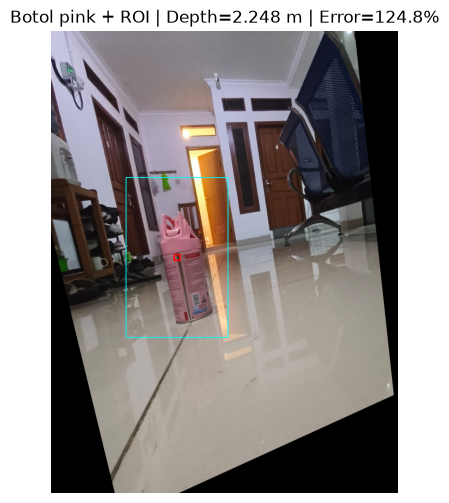

In [42]:
# === ISI HASIL PENGAMATAN ===
ROI_AUTO_PINK = True   # Gunakan pusat kotak deteksi botol pink
ROI_X = 510            # Dipakai jika ROI_AUTO_PINK = False
ROI_Y = 720            # Dipakai jika ROI_AUTO_PINK = False
ROI_RADIUS = 10        # jendela 21 x 21 piksel
Z_TRUE_M = 1.0         # GANTI: jarak sebenarnya dari meteran (meter)

if ROI_AUTO_PINK:
    ROI_X=(pink_box_l[0]+pink_box_l[2])//2
    ROI_Y=(pink_box_l[1]+pink_box_l[3])//2
h,w=Z.shape
if not (0<=ROI_X<w and 0<=ROI_Y<h):raise ValueError('ROI berada di luar gambar.')
x0,x1=max(0,ROI_X-ROI_RADIUS),min(w,ROI_X+ROI_RADIUS+1)
y0,y1=max(0,ROI_Y-ROI_RADIUS),min(h,ROI_Y+ROI_RADIUS+1)
roi_z=Z[y0:y1,x0:x1];roi_d=disp[y0:y1,x0:x1]
mask_roi=np.isfinite(roi_z)&(roi_z>0)
valid_count=int(mask_roi.sum())
if valid_count<10:
    fig,ax=plt.subplots(figsize=(8,6))
    ax.imshow(np.ma.masked_invalid(Z),cmap='viridis')
    ax.scatter([ROI_X],[ROI_Y],c='red',marker='x',s=80)
    ax.set_title('Depth valid dan posisi ROI — pilih titik pada area berwarna')
    ax.set_xlabel('X (piksel)');ax.set_ylabel('Y (piksel)');plt.show()
    raise RuntimeError(f'ROI ({ROI_X},{ROI_Y}) hanya memiliki {valid_count} piksel depth valid. Pilih titik berwarna pada peta depth di atas.')
Z_EST=float(np.median(roi_z[mask_roi]))
D_MED=float(np.median(roi_d[mask_roi]))
if Z_TRUE_M<=0:raise ValueError('Jarak meteran harus positif.')
ERROR_PCT=abs(Z_EST-Z_TRUE_M)/Z_TRUE_M*100
print(f'Piksel valid={valid_count} | disparity ROI={D_MED:.2f} px | Z estimasi={Z_EST:.3f} m | meteran={Z_TRUE_M:.3f} m | error={ERROR_PCT:.2f}%')
shown=cv2.cvtColor(left_u,cv2.COLOR_BGR2RGB).copy()
cv2.rectangle(shown,pink_box_l[:2],(pink_box_l[2]-1,pink_box_l[3]-1),(0,255,255),2)
cv2.rectangle(shown,(x0,y0),(x1-1,y1-1),(255,0,0),3)
plt.figure(figsize=(10,6));plt.imshow(shown);plt.title(f'Botol pink + ROI | Depth={Z_EST:.3f} m | Error={ERROR_PCT:.1f}%');plt.axis('off');plt.show()

## G — Simpan satu baris percobaan
Jalankan setiap kali mengukur jarak baru. **Sebelum uji berikutnya:** ganti foto `left.jpg/right.jpg`, lalu ulangi **D → G**. Jangan mengulang C bila parameter kamera tetap.

In [43]:
TEST_ID = 'uji_01'  # GANTI: uji_01, uji_02, uji_03
csv_path=OUT/'hasil_pengukuran.csv'
record={
    'uji':TEST_ID,'baseline_cm':BASELINE_CM,'square_size_mm':SQUARE_SIZE_MM,
    'fx_px':round(float(fx),3),'fy_px':round(float(fy),3),
    'rms_px':round(float(rms),3),'median_vertical_error_px':round(median_dy,3),
    'disparity_roi_px':round(D_MED,3),'depth_est_m':round(Z_EST,4),
    'depth_meter_m':round(Z_TRUE_M,4),'error_pct':round(ERROR_PCT,2)}
rows=[]
if csv_path.exists():
    with csv_path.open(encoding='utf-8',newline='') as fh:rows=list(csv.DictReader(fh))
rows=[r for r in rows if r['uji']!=TEST_ID]+[record]
with csv_path.open('w',encoding='utf-8',newline='') as fh:
    writer=csv.DictWriter(fh,fieldnames=list(record));writer.writeheader();writer.writerows(rows)
print('Tersimpan:',csv_path)
for r in rows:print(r['uji'],'| jarak meteran',r['depth_meter_m'],'m | estimasi',r['depth_est_m'],'m | error',r['error_pct'],'%')

Tersimpan: output\hasil_pengukuran.csv
uji_2 | jarak meteran 0.5 m | estimasi 3.2388 m | error 547.76 %
uji_3 | jarak meteran 1.5 m | estimasi 7.4751 m | error 398.34 %
uji_01 | jarak meteran 1.0 m | estimasi 2.2484 m | error 124.84 %


## Tugas analisis dan flowchart
**Ikuti format pengumpulan di README bagian 8.** Buat sendiri dua flowchart: (1) **A→B→C** dengan keputusan berhasil/gagal mendeteksi sudut; (2) **D→E→F→G** dengan keputusan alignment/ROI valid. Bandingkan minimal tiga jarak dan tulis penyebab error.

**Batasan:** proses ini menggunakan pendekatan translasi horizontal murni. Pemeriksaan alignment saja **tidak membuktikan** seluruh asumsi geometri terpenuhi; jangan melaporkan hasil sebagai jarak metrik terverifikasi tanpa perbandingan meteran.